---
title: "L4-02 · DAGs and d-separation"
short_title: "DAGs and d-separation"
subtitle: "A causal graph is a compact list of conditional independences: two sets are independent given $Z$ whenever every path between them is blocked by $Z$, and conditioning closes chains and forks but opens colliders."
description: "Use the chain, fork and collider rules to decide which conditional independences a causal graph implies, and justify the rules with the soundness theorem."
tags: [level-4, coursebook]
---

(lesson-l4-02)=

:::{div}
:class: qcai-meta
![Level 4 icon](../../_static/icons/qicon-level-4.svg) **Level 4 · Undergraduate** · about 100 minutes  
**Big idea.** A causal graph is a compact list of conditional independences: two sets are independent given $Z$ whenever every path between them is blocked by $Z$, and conditioning closes chains and forks but opens colliders.  
**Before this lesson.** [L4-01](#lesson-l4-01), [L2-07](#lesson-l2-07)  
**Lab.** [Confounding and intervention](../../labs/03-causal-inference.ipynb)
:::

## What you will be able to do

- Classify each interior node of a path as a chain, fork or collider node and decide whether the path is blocked by a given set $Z$.
- Decide d-separation in a graph with six or more nodes by enumerating paths and, independently, by the moralization test.
- State the soundness theorem precisely (which distributions, which direction) and verify it numerically with exact partial correlations.

## Why this matters

A graph with six variables can make $\binom{6}{2} \cdot 2^4 = 240$ statements of the form "these two are independent given that set". A causal model commits to some of them and not others, and data can test them. Checking 240 statements by integrating a joint distribution would be hopeless. The graph does it by reading paths.

Three tiny graphs carry all the logic. In a chain and a fork, the middle node passes dependence along until you condition on it. In a collider, the middle node stops dependence until you condition on it, and then it creates dependence that was not there. That second fact surprises almost everyone; it is behind selection bias, Berkson's paradox and many published errors. This lesson turns the three rules into one test, d-separation, proves that it never claims a false independence, and checks it numerically on a six-node graph [@pearlcausality; @spirtes; @peters].

:::{dropdown} Key terms

**Directed acyclic graph (DAG)**
: Nodes joined by arrows with no directed cycle; in a causal DAG an arrow means direct cause relative to the modeled variables.

**Path**
: A sequence of distinct nodes in which each consecutive pair is joined by an arrow in either direction.

**Collider**
: A node on a path where both neighboring arrows point in, as $C$ in $A \to C \leftarrow B$. Being a collider is a property of the node on that path.

**Blocked path**
: A path that contains a noncollider in $Z$, or a collider that is not in $Z$ and has no descendant in $Z$.

**d-separation**
: $X \perp_d Y \mid Z$: every path between $X$ and $Y$ is blocked by $Z$.

**Moral graph**
: The undirected graph obtained by joining every pair of parents of a common child and then dropping directions.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l4_02 as _lessonfigs

## Graphs as lists of independences

In [L4-01](#lesson-l4-01) a Markovian model gave the factorization $P(v) = \prod_i P(v_i \mid \mathrm{pa}_i)$ over its graph. We now forget the equations and keep only the graph, and ask which independences every such distribution must satisfy. Some vocabulary first, for a DAG $G$: the **parents** of $V$ have arrows into $V$; its **descendants** are the nodes reachable from $V$ along directed paths, including $V$ itself in this lesson; its **ancestors** are the nodes from which $V$ is reachable, again including $V$ itself, so the ancestors of a set always contain the set.

:::{prf:definition} Markov to a graph
:label: def-l4-02-markov
A distribution $P$ over $V$ is **Markov to** (factorizes over) a DAG $G$ if $P(v) = \prod_{i} P(v_i \mid \mathrm{pa}_i)$ for all $v$. Every Markovian SCM produces such a distribution (Theorem [](#thm-l4-01-markov)).
:::

```{mermaid}
graph TD
  A((A)) --> C((C))
  B((B)) --> C
  C --> D((D))
  B --> E((E))
  D --> F((F))
  E --> F
```

*The running six-node graph. There are two paths between $A$ and $E$: $A \to C \leftarrow B \to E$ and $A \to C \to D \to F \leftarrow E$. Each contains a collider ($C$ on the first, $F$ on the second).*

A **path** may follow arrows in either direction. The same node can be a collider on one path and not on another: $C$ is a collider on $A \to C \leftarrow B \to E$ but a chain node on $A \to C \to D \to F \leftarrow E$.

## Chains, forks and colliders

:::{figure} ../../_static/animations/l4_02_three_junctions.mp4
:alt: Chain, fork and collider side by side; a token passes through the chain and fork but stops at the collider; after conditioning on the middle node the results reverse.
:width: 100%

Conditioning on the middle node closes chains and forks, and opens colliders.
:::

:::{dropdown} What the animation shows
Three small graphs stand side by side: a chain $X \to M \to Y$, a fork $X \leftarrow M \to Y$ and a collider $X \to M \leftarrow Y$. With nothing conditioned on, an orange token travels from $X$ toward $Y$ in each graph. It passes through the chain and the fork, which are marked open, and stops at the middle of the collider, which is crossed out and marked blocked. Then the three middle nodes turn grey, meaning we condition on $M$. Now the token stops at $M$ in the chain and the fork (blocked) and passes through the collider (open). Under each graph the rule is written: $X \perp\!\!\!\perp Y \mid M$ for the chain and the fork, and for the collider $X$ and $Y$ are independent but not given $M$. The final line says: conditioning on the middle closes chains and forks, and opens colliders.
:::

:::{prf:proposition} The three junctions
:label: prop-l4-02-junctions
Let $P$ be Markov to a three-node graph. (a) Chain $X \to M \to Y$ and (b) fork $X \leftarrow M \to Y$: $X \perp\!\!\!\perp Y \mid M$. (c) Collider $X \to M \leftarrow Y$: $X \perp\!\!\!\perp Y$, and there are distributions Markov to the collider in which $X$ and $Y$ are dependent given $M$.
:::

:::{prf:proof}
(a) $P(x, m, y) = P(x) P(m \mid x) P(y \mid m)$, so $P(y \mid x, m) = P(x, m, y)/P(x, m) = P(y \mid m)$, which does not depend on $x$. (b) $P(x, m, y) = P(m) P(x \mid m) P(y \mid m)$; divide by $P(m)$ to get $P(x, y \mid m) = P(x \mid m) P(y \mid m)$. (c) $P(x, m, y) = P(x) P(y) P(m \mid x, y)$; summing over $m$ gives $P(x, y) = P(x)P(y)$. For dependence given $M$, let $X$ and $Y$ be fair coins and $M = X \oplus Y$ (exclusive or). Given $M = 0$, $Y = X$ with certainty, so $P(Y = 1 \mid X = 1, M = 0) = 1 \ne 1/2 = P(Y = 1 \mid M = 0)$.
:::


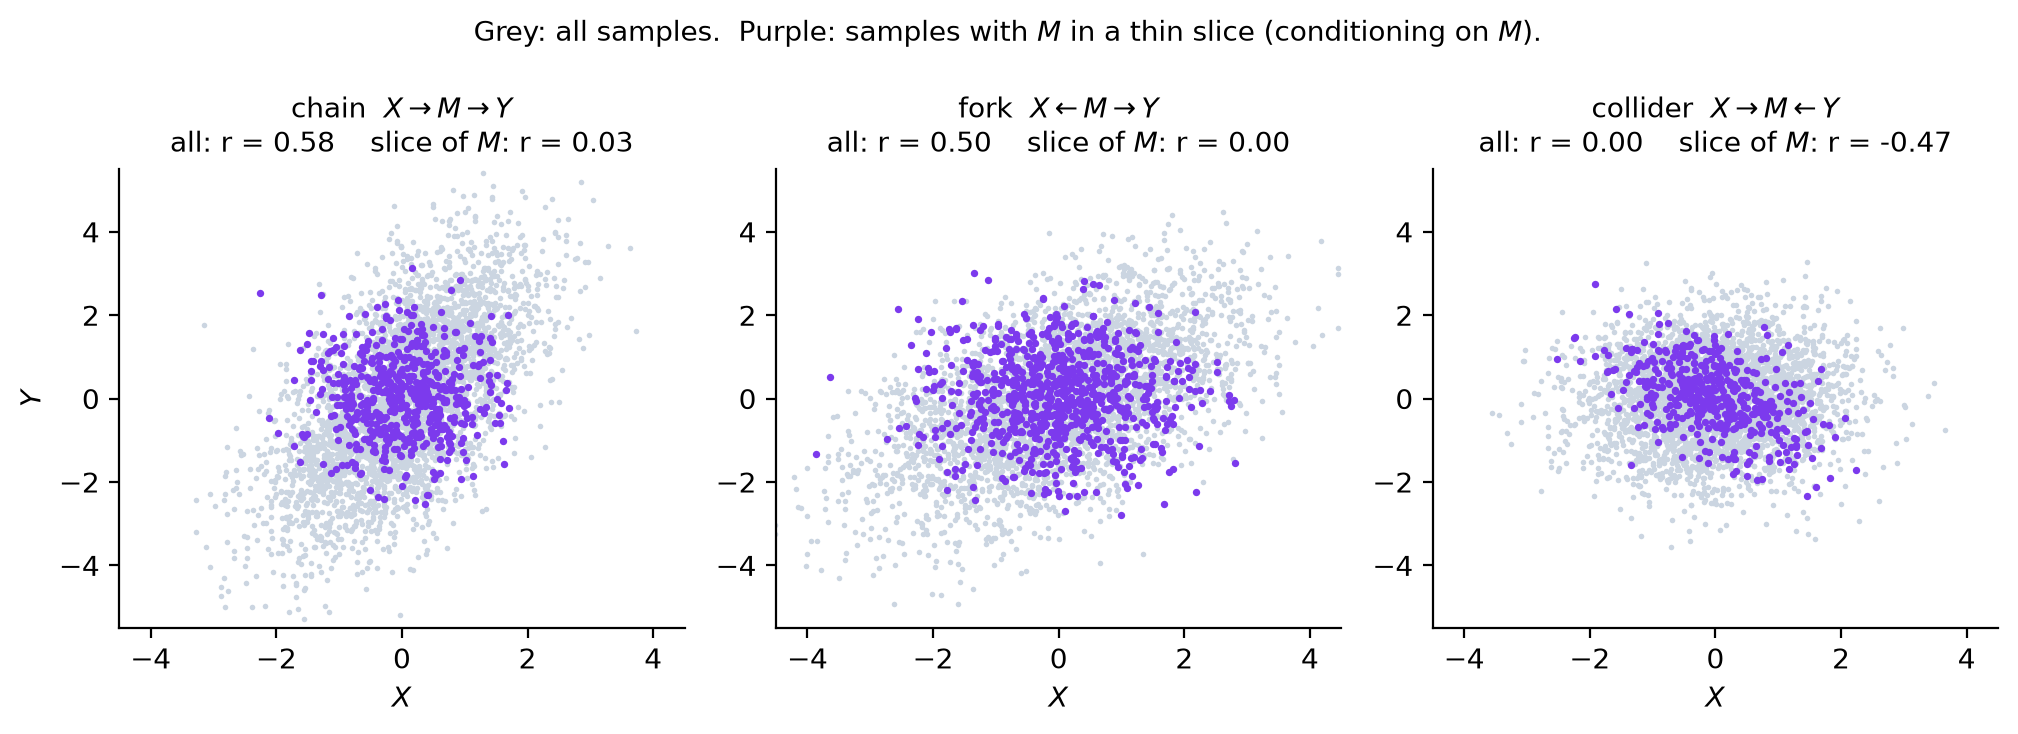

In [2]:
_show_mpl(_lessonfigs.junction_scatter())

*Linear-Gaussian versions of the three junctions, 4000 samples each. Overall, $X$ and $Y$ are correlated in the chain and the fork and uncorrelated in the collider. Inside a thin slice of $M$ (purple), the correlation vanishes for the chain and the fork and appears (negative) for the collider. The population values are $1/\sqrt3 \approx 0.58$, $0.5$ and $0$ overall, and $0$, $0$ and $-0.5$ given $M$.*

:::{warning} Descendants of a collider count too
Conditioning on a descendant of a collider also opens the collider. If $D$ is a noisy copy of $C$ in $A \to C \leftarrow B$, then learning $D$ tells you something about $C$, and that is enough to couple $A$ and $B$. This is why the definition below mentions descendants.
:::

## d-separation

:::{prf:definition} Blocked paths and d-separation
:label: def-l4-02-dsep
Let $Z$ be a set of nodes. A path $p$ is **blocked** by $Z$ if it has an interior node $W$ such that either (i) $W$ is a noncollider on $p$ and $W \in Z$, or (ii) $W$ is a collider on $p$ and neither $W$ nor any descendant of $W$ is in $Z$. For pairwise disjoint sets $X$, $Y$ and $Z$, the sets $X$ and $Y$ are **d-separated** by $Z$, written $X \perp_d Y \mid Z$, if every path between a node of $X$ and a node of $Y$ is blocked by $Z$. Otherwise they are **d-connected** [@pearlcausality; @spirtes]. Later lessons also write $X \perp_d Y \mid Z$ as $(X \perp\!\!\!\perp Y \mid Z)_G$, with the graph as a subscript.
:::

Apply it to the running graph with $X = \{A\}$ and $Y = \{E\}$. With $Z = \emptyset$, path 1 is blocked at the collider $C$ and path 2 at the collider $F$, so $A \perp_d E$. With $Z = \{D\}$, the collider $C$ on path 1 has the descendant $D$ in $Z$, so it no longer blocks, and $B$ is an unconditioned noncollider; path 1 is open, so $A \not\perp_d E \mid \{D\}$. With $Z = \{B, D\}$, path 1 is blocked at $B$ and path 2 at $D$, so $A \perp_d E \mid \{B, D\}$.

:::{figure} ../../_static/animations/l4_02_dsep_sweep.mp4
:alt: The six-node graph with two paths between A and E walked by a token for three conditioning sets; blocking nodes are crossed out and three verdicts are written.
:width: 100%

Walk every path node by node. Adding $D$ opens a collider through its descendant; adding $B$ as well closes the path again.
:::

:::{dropdown} What the animation shows
The six-node graph has arrows $A \to C$, $B \to C$, $C \to D$, $B \to E$, $D \to F$ and $E \to F$. The question is whether $A$ and $E$ are d-separated by a set $Z$. Two paths connect them: path 1, $A \to C \leftarrow B \to E$, and path 2, $A \to C \to D \to F \leftarrow E$. Round one, $Z$ empty: a token walks path 1 and stops at the collider $C$; it walks path 2 and stops at the collider $F$. The verdict $A \perp_d E$ is written. Round two, $Z = \{D\}$ (D turns grey): on path 1 the collider $C$ now has a conditioned descendant $D$, so the token passes $C$ and the unconditioned noncollider $B$ and reaches $E$; the path is marked open. Path 2 is blocked at $D$, a noncollider in $Z$. The verdict is $A \not\perp_d E \mid \{D\}$. Round three, $Z = \{B, D\}$: path 1 is blocked at $B$ and path 2 at $D$, so $A \perp_d E \mid \{B, D\}$. The three verdicts stay on screen in a box.
:::


In [3]:
_show(_lessonfigs.dsep_explorer())

**Explore.** Choose a conditioning set with the buttons. Grey nodes are conditioned on; open paths between $A$ and $E$ are highlighted in orange, and the title gives the verdict and the first blocking node of each path.

:::{dropdown} What the figure shows
The six-node graph is drawn with arrows. Buttons choose $Z$ from $\emptyset$, $\{C\}$, $\{D\}$, $\{F\}$, $\{B\}$, $\{B, D\}$ and $\{B, C\}$. For $\emptyset$, $\{B\}$, $\{B, D\}$ and $\{B, C\}$ no path is highlighted and the title says d-separated. For $\{C\}$ and $\{D\}$ path $A - C - B - E$ is highlighted and the title says d-connected. For $\{F\}$ both paths are highlighted, because $F$ is a collider on path 2 and a descendant of the collider $C$ on path 1.
:::

:::{prf:algorithm} Deciding $X \perp_d Y \mid Z$ without listing paths
:label: alg-l4-02-moral
1. Keep only the ancestors of $X \cup Y \cup Z$ (including those sets).
2. Moralize: join every pair of parents that share a child, then drop all directions.
3. Delete the nodes of $Z$ and their edges.
4. Answer **d-separated** if no node of $X$ can reach a node of $Y$ in what is left.

The number of paths can grow exponentially with the size of the graph; this test needs only graph search, so it runs in time linear in the number of edges after moralization.
:::

## Why the rules are right

:::{prf:theorem} Soundness of d-separation (global Markov property)
:label: thm-l4-02-soundness
Let $G$ be a DAG and $X, Y, Z$ disjoint sets of its nodes. If $X \perp_d Y \mid Z$ in $G$, then $X \perp\!\!\!\perp Y \mid Z$ in **every** distribution $P$ that is Markov to $G$ [@geiger1990; @lauritzen1990; @pearlcausality; @spirtes; @peters].
:::

:::{prf:lemma} Moralization criterion
:label: lem-l4-02-moral
$X \perp_d Y \mid Z$ in $G$ if and only if $Z$ separates $X$ from $Y$ in the moral graph of the subgraph of $G$ induced by the ancestors of $X \cup Y \cup Z$. This equivalence, used by the algorithm above, is due to Lauritzen, Dawid, Larsen and Leimer (1990) [@lauritzen1990]; its proof is a careful but elementary argument about paths.
:::

:::{prf:proof}
*Proof sketch of the theorem, assuming the lemma.* Let $\mathcal A$ be the ancestors of $X \cup Y \cup Z$.

**Step 1 (marginalize to an ancestral set).** Summing $\prod_i P(v_i \mid \mathrm{pa}_i)$ over a node with no children removes exactly its own factor, because that factor sums to 1 and no other factor mentions the node. Nodes outside $\mathcal A$ can be removed one at a time this way, childless first, so $P(v_{\mathcal A}) = \prod_{i \in \mathcal A} P(v_i \mid \mathrm{pa}_i)$.

**Step 2 (factors live on cliques of the moral graph).** Each factor depends on a node and its parents. In the moral graph these are pairwise joined, so $P(v_{\mathcal A}) = \prod_c \psi_c(v_c)$ with every $c$ a clique of the moral ancestral graph $H$.

**Step 3 (separation gives independence).** By the lemma, $Z$ separates $X$ from $Y$ in $H$. Let $R$ be the nodes that $X$ can reach in $H$ after deleting $Z$, and $W$ the remaining nodes outside $R \cup Z$, so $Y \subseteq W$. No clique meets both $R$ and $W$ (its nodes would be adjacent, and $W$ would be reachable). Grouping the factors gives $P(v_{\mathcal A}) = f(v_R, v_Z)\, g(v_W, v_Z)$, and a joint density of this form satisfies $R \perp\!\!\!\perp W \mid Z$. Since $X \subseteq R$ and $Y \subseteq W$, $X \perp\!\!\!\perp Y \mid Z$.
:::

:::{figure} ../../_static/animations/l4_02_moralize_proof.mp4
:alt: The six-node graph is reduced step by step: F is removed, A and B are joined, arrows become lines, D is deleted, and the surviving path A - B - E is highlighted; then B is deleted too.
:width: 100%

The moralization test on the running graph. It gives the same verdicts as walking paths, and it is the bridge from the graph to the factorization in the soundness proof.
:::

:::{dropdown} What the animation shows
The same six-node graph is used to answer whether $A$ and $E$ are d-separated by $\{D\}$, with the moralization test. Step 1 keeps only the ancestors of $A$, $E$ and $D$: node $F$ and its two incoming arrows fade away. Step 2 marries the parents of a common child: a red dashed line joins $A$ and $B$, the two parents of $C$. Step 3 drops all directions, so every arrow becomes a plain line. Step 4 deletes the conditioning set: $D$ and its line disappear. Step 5 asks whether $A$ can still reach $E$: the path $A - B - E$ lights up, so the verdict is $A \not\perp_d E \mid \{D\}$. Then $B$ is deleted as well, which leaves $A$ joined only to $C$ and $E$ isolated, so $A \perp_d E \mid \{B, D\}$. The closing line states the criterion: d-separated in $G$ if and only if separated in the moral ancestral graph.
:::

:::{prf:remark} Completeness and faithfulness are separate statements
Soundness goes one way: d-separation implies independence. The converse fails for particular distributions: a distribution can have extra independences that the graph does not imply (exercise 5 builds one by cancelling two paths). What is true is **completeness** [@geiger1990]: if $X \not\perp_d Y \mid Z$, then *some* distribution Markov to $G$ has $X$ and $Y$ dependent given $Z$; for linear-Gaussian models with coefficients drawn from a density, the cancelling choices have probability zero [@spirtes; @pearlcausality]. Assuming that the true distribution has no extra independences is the **faithfulness** assumption, which causal discovery in [L4-08](#lesson-l4-08) relies on.
:::

## Compute it

Implement the moralization test and compare it with networkx on all 240 statements the six-node graph can make about pairs of nodes.


In [4]:
import itertools
import networkx as nx
import numpy as np

nodes = ["A", "B", "C", "D", "E", "F"]
edges = [("A", "C"), ("B", "C"), ("C", "D"), ("B", "E"), ("D", "F"), ("E", "F")]
G = nx.DiGraph(edges)

def d_separated(G, xs, ys, zs):
    # moralization criterion: ancestral subgraph -> marry parents -> drop directions -> delete zs -> reachability
    keep = set().union(*(nx.ancestors(G, v) | {v} for v in set(xs) | set(ys) | set(zs)))
    H = G.subgraph(keep)
    M = nx.Graph(H.to_undirected())
    for v in H:
        M.add_edges_from(itertools.combinations(list(H.predecessors(v)), 2))
    M.remove_nodes_from(zs)
    reach = set().union(*(nx.node_connected_component(M, x) for x in xs))
    return not (reach & set(ys))

statements = []
for x, y in itertools.combinations(nodes, 2):
    rest = [v for v in nodes if v not in (x, y)]
    for k in range(len(rest) + 1):
        for zs in itertools.combinations(rest, k):
            statements.append((x, y, set(zs)))

ours = [d_separated(G, {x}, {y}, zs) for x, y, zs in statements]
theirs = [nx.is_d_separator(G, {x}, {y}, zs) for x, y, zs in statements]
print("statements checked:", len(statements), " agree with networkx:", ours == theirs)
print("d-separations that hold:", sum(ours))
for zs in [set(), {"D"}, {"B", "D"}, {"F"}]:
    print("A, E given", sorted(zs) or "{}", "->", "d-separated" if d_separated(G, {"A"}, {"E"}, zs) else "d-connected")

statements checked: 240  agree with networkx: True
d-separations that hold: 56
A, E given {} -> d-separated
A, E given ['D'] -> d-connected
A, E given ['B', 'D'] -> d-separated
A, E given ['F'] -> d-connected


Soundness checked exactly. In a linear-Gaussian model, conditional independence is a zero partial correlation, and the covariance matrix follows from the coefficients. With generic coefficients the zeros appear exactly at the d-separations, and a large sample gives the same verdicts up to sampling noise.


In [5]:
# Soundness, checked exactly: a linear-Gaussian SCM on G with generic coefficients.
# V = B V + N with independent unit-variance noise, so Cov(V) = (I - B)^-1 (I - B)^-T.
rng = np.random.default_rng(3)
idx = {v: i for i, v in enumerate(nodes)}
B = np.zeros((6, 6))
for a, b in edges:
    B[idx[b], idx[a]] = rng.uniform(0.5, 1.5) * rng.choice([-1, 1])
A_ = np.linalg.inv(np.eye(6) - B)
Sigma = A_ @ A_.T

def pcorr(S, i, j, cond):
    sub = [i, j] + list(cond)
    K = np.linalg.inv(S[np.ix_(sub, sub)])
    return -K[0, 1] / np.sqrt(K[0, 0] * K[1, 1])

rho = np.array([abs(pcorr(Sigma, idx[x], idx[y], [idx[z] for z in zs])) for x, y, zs in statements])
sep = np.array(ours)
print("largest |partial corr| among d-separated pairs:", f"{rho[sep].max():.1e}")
print("smallest |partial corr| among d-connected pairs:", f"{rho[~sep].min():.3f}")

# The same verdicts from 200 000 samples
n = 200_000
V = rng.normal(size=(n, 6)) @ A_.T
Ssamp = np.cov(V, rowvar=False)
for zs in [set(), {"D"}, {"B", "D"}]:
    r = pcorr(Ssamp, idx["A"], idx["E"], [idx[z] for z in zs])
    print("sample partial corr of A, E given", sorted(zs) or "{}", "=", round(r, 4))

largest |partial corr| among d-separated pairs: 7.4e-16
smallest |partial corr| among d-connected pairs: 0.029
sample partial corr of A, E given {} = 0.0028
sample partial corr of A, E given ['D'] = 0.1598
sample partial corr of A, E given ['B', 'D'] = 0.0032


## Worked example

:::{admonition} Conditioning on a common descendant
:class: tip

In the running graph, are $A$ and $E$ d-separated by $Z = \{F\}$?

1. List the paths: $A \to C \leftarrow B \to E$ and $A \to C \to D \to F \leftarrow E$.
2. Path 1: the collider $C$ is not in $Z$, but its descendant $F$ is, so $C$ does not block. $B$ is a noncollider not in $Z$, so it does not block. Path 1 is open.
3. Path 2: $C$ and $D$ are noncolliders not in $Z$; $F$ is a collider in $Z$. Nothing blocks, so path 2 is open too.
4. Check with the moralization test: the ancestors of $\{A, E, F\}$ are all six nodes; marrying the parents of $C$ and of $F$ adds $A - B$ and $D - E$; deleting $F$ leaves $A - B - E$ and $A - C - D - E$, so $A$ reaches $E$.

**Result.** $A \not\perp_d E \mid \{F\}$, through two open paths. Conditioning on a common descendant of colliders can open several paths at once.
:::

## Exercises

**1. (Core)** In the graph $A \leftarrow Z \to B$ with no other edges, are $A$ and $B$ d-separated with no conditioning? What changes when you condition on $Z$?

:::{dropdown} Solution
The only path $A \leftarrow Z \to B$ has the fork node $Z$, a noncollider. With $Z$ not conditioned on, nothing blocks it, so $A$ and $B$ are d-connected. Conditioning on $Z$ blocks the only path, so $A \perp_d B \mid Z$.
:::

**2. (Core)** In the running graph, decide whether $B \perp_d D \mid \{C\}$, and whether $B \perp_d D \mid \{C, F\}$.

:::{dropdown} Solution
Paths between $B$ and $D$: $B \to C \to D$ and $B \to E \to F \leftarrow D$. Given $\{C\}$: the first is blocked at the noncollider $C$; the second at the collider $F$ (not conditioned, no descendants). So $B \perp_d D \mid \{C\}$. Given $\{C, F\}$: the first is still blocked at $C$, but $F$ is now a conditioned collider and $E$ an unconditioned noncollider, so the second path is open: $B \not\perp_d D \mid \{C, F\}$.
:::

**3. (Stretch)** Prove the local Markov property from d-separation: in any DAG, a node $V$ is d-separated from each non-descendant $W$ (not a parent) by its parents $\mathrm{PA}_V$.

:::{dropdown} Solution
Take a path from $V$ to $W$. If its first edge is $V \leftarrow P$, then $P$ is a parent, and on the path the edge at $P$ has its tail at $P$, so $P$ is a noncollider in $Z = \mathrm{PA}_V$: blocked. If its first edge is $V \to C$, follow the path. It cannot be directed all the way, or $W$ would be a descendant of $V$. So there is a first node where two arrowheads meet, a collider $K$, reached from $V$ by a directed path; $K$ and all its descendants are descendants of $V$. None of them is a parent of $V$, since that would create a directed cycle. So $K$ blocks the path. Every path is blocked.
:::

**4. (Stretch)** Let $X$ and $Y$ be independent fair coins and $M = X \oplus Y$. Show that $X \perp\!\!\!\perp Y$, that $X$ and $Y$ are dependent given $M$, and that $X \perp\!\!\!\perp M$ even though the graph has the arrow $X \to M$. Which assumption does the last fact violate?

:::{dropdown} Solution
$X$ and $Y$ are independent by construction. Given $M = 0$, $Y = X$; given $M = 1$, $Y = 1 - X$; so each determines the other given $M$. For $X$ and $M$: $P(M = 1 \mid X = x) = P(Y \ne x) = 1/2$ for both $x$, so $X \perp\!\!\!\perp M$. The graph has $X \to M$, so $X$ and $M$ are d-connected; an independence the graph does not imply violates faithfulness. Soundness is not violated: it only promises independences, never dependences.
:::

**5. (Challenge)** In the linear model $M := aX + N_M$, $Y := bX + gM + N_Y$ with independent noises, find a choice of coefficients with $a, b, g$ all nonzero that makes $X \perp\!\!\!\perp Y$. Explain why this does not contradict the soundness theorem, and what it says about inferring the graph from independences.

:::{dropdown} Solution
$Y = (b + ga)X + gN_M + N_Y$, so $\mathrm{Cov}(X, Y) = (b + ga)\mathrm{Var}(X)$. Choosing $b = -ga$ (for example $a = 1$, $g = 2$, $b = -2$) gives zero covariance, hence independence in the Gaussian case. Soundness only says that d-separations imply independences; here an independence holds without d-separation, which is allowed. It shows that a single distribution can hide arrows that exist, so learning a graph from independences needs faithfulness, which rules out exact cancellations like $b = -ga$.
:::

**6. (Challenge)** In the running graph, how many of the 16 subsets $Z$ of $\{B, C, D, F\}$ d-separate $A$ from $E$? Characterize them.

:::{dropdown} Solution
Eight. If $Z$ contains $B$, path 1 is blocked at $B$, and path 2 is blocked at $C$ or $D$ if either is in $Z$, or else at the collider $F$ if $F \notin Z$; the only failure would be $Z = \{B, F\}$, and indeed $\{B, F\}$ leaves path 2 open. So the seven sets containing $B$ other than $\{B, F\}$ work: $\{B\}$, $\{B, C\}$, $\{B, D\}$, $\{B, C, D\}$, $\{B, C, F\}$, $\{B, D, F\}$, $\{B, C, D, F\}$. If $Z$ omits $B$, path 1 is blocked only if the collider $C$ has no descendant in $Z$, that is $Z \cap \{C, D, F\} = \emptyset$, so $Z = \emptyset$, which also blocks path 2 at $F$. Total $7 + 1 = 8$, as the code confirms.
:::

## Check your understanding

**1. In the collider $X \to M \leftarrow Y$ with no other edges, what does conditioning on $M$ do to the path between $X$ and $Y$?**

- **A.** It has no effect because the path was already open
- **B.** It opens the path, so $X$ and $Y$ can become dependent
- **C.** It blocks the path
- **D.** It reverses the arrows

:::{dropdown} Show the answer
**B. It opens the path, so $X$ and $Y$ can become dependent**

A collider blocks a path unless it, or one of its descendants, is conditioned on. Conditioning on $M$ opens the path.
:::

**2. In the running graph, why are $A$ and $E$ d-connected given $\{D\}$?**

- **A.** $D$ blocks $A \to C \to D \to F \leftarrow E$
- **B.** $D$ is a descendant of the collider $C$, which opens $A \to C \leftarrow B \to E$
- **C.** $A$ is a parent of $E$
- **D.** Conditioning always creates dependence

:::{dropdown} Show the answer
**B. $D$ is a descendant of the collider $C$, which opens $A \to C \leftarrow B \to E$**

$D$ does block path 2, but a single open path is enough for d-connection, and path 1 opens because the collider $C$ has the conditioned descendant $D$ while $B$ is unconditioned.
:::

**3. What does the soundness theorem guarantee?**

- **A.** The graph can be recovered uniquely from data
- **B.** If $X \perp_d Y \mid Z$, then $X \perp\!\!\!\perp Y \mid Z$ in every distribution Markov to $G$
- **C.** Every d-connected pair has a nonzero causal effect
- **D.** If $X$ and $Y$ are independent given $Z$ in the data, then $X \perp_d Y \mid Z$

:::{dropdown} Show the answer
**B. If $X \perp_d Y \mid Z$, then $X \perp\!\!\!\perp Y \mid Z$ in every distribution Markov to $G$**

Soundness runs from the graph to the distribution. The reverse direction needs faithfulness, and d-connection does not imply a causal effect (a fork creates dependence without one).
:::

**4. Which junction is $X \leftarrow M \to Y$?** *(Review of [L2-07](#lesson-l2-07))*

- **A.** None of these
- **B.** A chain
- **C.** A collider
- **D.** A fork (common cause)

:::{dropdown} Show the answer
**D. A fork (common cause)**

Both arrows leave $M$, so $M$ is a common cause of $X$ and $Y$: a fork. Conditioning on $M$ blocks it.
:::

## Common misconceptions

- **"Conditioning on more variables can only remove spurious association."** Conditioning on a collider, or on a descendant of one, creates association. In the running graph $A \perp_d E$ holds with nothing conditioned on, and fails once $D$ is added.
- **"If two variables are d-connected they must be dependent in the data."** Soundness only guarantees independences. Exact cancellations (exercise 5) or functions like exclusive or (exercise 4) can make d-connected variables independent; ruling this out is the faithfulness assumption.
- **"A collider is a type of variable."** Being a collider is a property of a node on a particular path. $C$ is a collider on $A \to C \leftarrow B \to E$ and a chain node on $A \to C \to D \to F \leftarrow E$.

:::{caution} Scope and limits
d-separation is a statement about a stated graph. If the graph omits a common cause, a selection mechanism, or a feedback loop, the implied independences can be wrong. The theorem gives independences for every distribution that factorizes over the graph; it never guarantees dependences, and detecting an independence in finite data is a statistical test with its own error rates. The numerical checks in this lesson use exact covariances of linear-Gaussian models, where independence is the same as zero partial correlation; for other distributions zero correlation does not imply independence.
:::

:::{seealso} Where this leads
d-separation is the engine of the next three lessons. [L4-03](#lesson-l4-03) uses it to sort variables into confounders, mediators and colliders; [L4-04](#lesson-l4-04) states the backdoor criterion as a d-separation in a modified graph; [L4-08](#lesson-l4-08) runs it backwards, from tested independences to graphs. In Level 6, quantum causal models keep a version of d-separation even though they give up classical hidden variables.
:::

:::{dropdown} For instructors

**Why this lesson.** Students can memorize the three junctions and still fail on graphs with several paths and descendants of colliders. Walking paths node by node, then confirming with the moralization test, gives two independent procedures that must agree, and the soundness proof shows why the rules are not arbitrary [@pearlcausality; @spirtes; @peters].

**Teaching notes.**

- Start with the junction figure: ask students to predict the slice correlation for each panel before revealing it. The collider panel is the one they get wrong.
- Make students write "blocked at ... because ..." for each path; most errors come from forgetting the descendant clause or treating a node as a collider on every path.
- Use the interactive to collect the separating sets for $A$ and $E$ and conjecture the pattern before the last challenge exercise.
- The proof sketch has three steps that can be done on the board in ten minutes; leave the lemma's path argument as reading.

**Assessment.** The second core exercise and the worked example test path reading with colliders and descendants; the stretch proof of the local Markov property tests whether students can reason about arbitrary paths; the challenge exercise on cancellation tests the difference between soundness and faithfulness.

**Going further.** Have students implement the reachability (Bayes-ball) version of d-separation, which follows active trails instead of moralizing, and compare it with networkx on random DAGs. Peters, Janzing and Schölkopf discuss the Markov properties and their equivalence in detail [@peters].

:::

## References

This lesson draws on [@pearlcausality; @spirtes; @peters; @pearl; @bradyneal; @geiger1990; @lauritzen1990].

**Further reading.**

- [@bradyneal]: The chapter on graphical models gives the junctions and d-separation with many small examples.
- [@causallearn]: A Python library whose independence tests and discovery algorithms build on these rules.

**Next:** [L4-03 · Confounders, mediators, and colliders](#lesson-l4-03)
